# 10 · Explainability: why does a model say "phishing"? (Milestone 6)

An accuracy number doesn't tell us *what* a model learned. Here we open the models up:

| Question | Method | Model |
|---|---|---|
| Which **features** matter, overall and for one URL? | **SHAP** (TreeSHAP, exact for trees) | XGBoost on the 40 URL features |
| Which features does the **hybrid** rely on? | **Permutation importance**: shuffle one feature, measure the drop | Hybrid (features branch) |
| Which **characters** made the hybrid say phishing? | **Occlusion**: hide one character, measure the change | Hybrid (characters branch) |
| Are the explanations **right**? | **Deletion test**: remove the "most important" characters, see if the prediction really changes | Hybrid |

All scores are in **log-odds**, where contributions add up. **Red / positive = pushes towards phishing, blue / negative = towards legitimate.**

Code: `src/phishguard/explain.py`. We explain the **seed-42** models of notebooks 07 and 09, retrained here with the settings they chose on validation, because `experiment.run()` doesn't keep trained models.

In [1]:
# Import phishguard.deep first: on macOS it makes torch and xgboost share CPU threads safely.
from phishguard.deep import CharURLClassifier
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import HTML, display
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET, REPO_ROOT
from phishguard.urls import URL_VIEWS, TLD_EXTRACT
from phishguard.features import extract_features
from phishguard.split import get_splits
from phishguard.evaluate import evaluate, best_threshold
from phishguard.experiment import load_record
from phishguard.explain import char_occlusion, feature_occlusion, tree_shap, highlight, explain_url

df = load_clean()
y = df[TARGET]
train_idx, val_idx, test_idx = get_splits(df, seed=42)
VIEWS = ["raw URL", "domain only"]
inputs = {}
for view in VIEWS:
    text = URL_VIEWS[view](df["URL"])
    inputs[view] = extract_features(text).assign(url=text)
feature_cols = [c for c in inputs["raw URL"].columns if c != "url"]

## 1. The models we explain (seed-42 split)

In [2]:
make_xgb = lambda: XGBClassifier(max_depth=6, n_estimators=500, learning_rate=0.1, subsample=0.8,
                                 colsample_bytree=0.8, random_state=42)
hybrids, xgbs, rows = {}, {}, []
for view in VIEWS:
    X = inputs[view]
    params = load_record("m5_hybrid", f"Hybrid CNN + features | {view}")["reference"]["params"]
    model = CharURLClassifier(arch="hybrid", **params).fit(X.loc[train_idx], y.loc[train_idx])
    threshold = best_threshold(y.loc[val_idx], model.predict_proba(X.loc[val_idx])[:, 1])
    hybrids[view] = (model, threshold)
    xgbs[view] = make_xgb().fit(X.loc[train_idx, feature_cols], y.loc[train_idx])
    xgb_threshold = best_threshold(y.loc[val_idx], xgbs[view].predict_proba(X.loc[val_idx, feature_cols])[:, 1])
    rows.append({
        "view": view, "hybrid settings": params,
        "hybrid test accuracy (retrained)": evaluate(y.loc[test_idx], model.predict_proba(X.loc[test_idx])[:, 1], threshold)["accuracy"],
        "hybrid test accuracy (notebook 09)": load_record("m5_hybrid", f"Hybrid CNN + features | {view}")["reference"]["test"]["accuracy"],
        "XGBoost test accuracy": evaluate(y.loc[test_idx], xgbs[view].predict_proba(X.loc[test_idx, feature_cols])[:, 1], xgb_threshold)["accuracy"],
    })
pd.DataFrame(rows)

,view,hybrid settings,hybrid test accuracy (retrained),hybrid test accuracy (notebook 09),XGBoost test accuracy
0,raw URL,{'dropout': 0.3},0.997495,0.997381,0.996869
1,domain only,{'dropout': 0.5},0.877768,0.880473,0.801936


The retrained hybrids land close to notebook 09. They aren't bit-identical, because GPU arithmetic isn't deterministic (D12).

We save the domain-only hybrid and its threshold for the Streamlit app (Milestone 8), so the app doesn't have to retrain it.

In [3]:
models_dir = REPO_ROOT / "models"
models_dir.mkdir(exist_ok=True)
model, threshold = hybrids["domain only"]
model.save(models_dir / "hybrid_domain_only.pt")
(models_dir / "hybrid_domain_only.json").write_text(json.dumps({
    "view": "domain only", "threshold": threshold, "trained_on": "seed-42 train split",
    "settings": model.arch_options, "test_accuracy": rows[1]["hybrid test accuracy (retrained)"],
}, indent=2))
print(sorted(p.name for p in models_dir.iterdir()), f"| threshold {threshold:.2f}")

['hybrid_domain_only.json', 'hybrid_domain_only.pt'] | threshold 0.54


## 2. SHAP for XGBoost: which features matter?

**SHAP** gives every feature a share of the prediction, so that

  base value (average log-odds) + sum of the SHAP values = the model's log-odds for this URL.

It comes from game theory (Shapley values): a feature's share is its average contribution over all orders of adding the features. For trees, `TreeExplainer` computes it **exactly**. We check the "adds up" property on real data first.

In [4]:
rng = np.random.default_rng(0)
sample = rng.choice(test_idx, size=2000, replace=False)
explanations = {}
for view in VIEWS:
    explanation = tree_shap(xgbs[view], inputs[view].loc[sample, feature_cols])
    log_odds = xgbs[view].predict(inputs[view].loc[sample, feature_cols], output_margin=True)
    gap = np.abs(explanation.base_values + explanation.values.sum(axis=1) - log_odds).max()
    print(f"{view}: base value {explanation.base_values[0]:+.2f}, largest gap between SHAP sum and model output {gap:.1e}")
    explanations[view] = explanation

raw URL: base value -0.30, largest gap between SHAP sum and model output 1.9e-05


domain only: base value -0.29, largest gap between SHAP sum and model output 1.4e-05


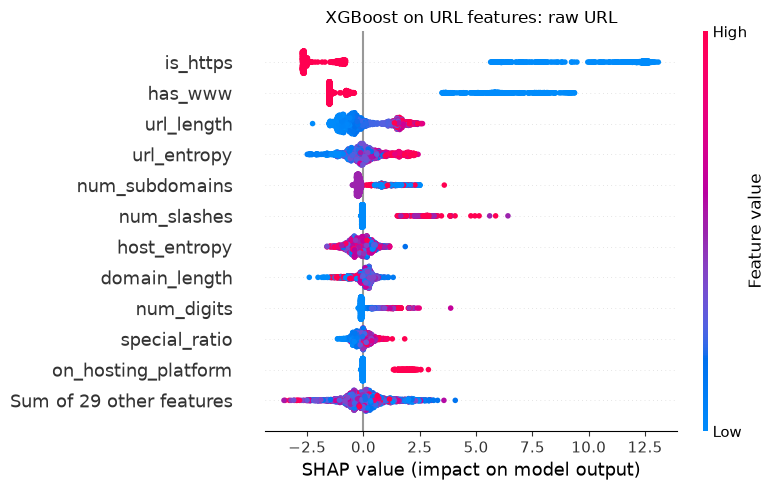

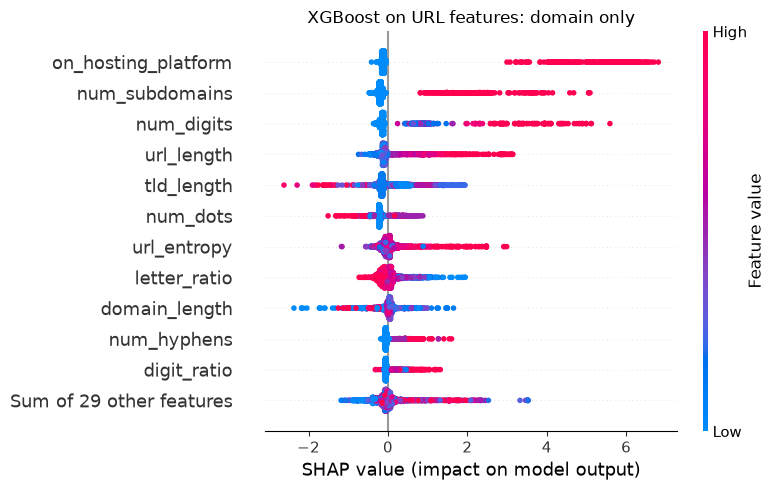

In [5]:
for view in VIEWS:
    shap.plots.beeswarm(explanations[view], max_display=12, show=False)
    plt.title(f"XGBoost on URL features: {view}")
    plt.gcf().set_size_inches(8, 5)
    plt.tight_layout()
    plt.show()

**How to read a beeswarm:** one dot per URL. The position is the SHAP value (right = towards phishing), and the colour is the feature's value (red = high, blue = low). Features are sorted by mean |SHAP|.

In [6]:
importance = pd.DataFrame({view: np.abs(explanations[view].values).mean(axis=0) for view in VIEWS}, index=feature_cols)
pd.concat({view: importance[view].nlargest(10).reset_index().set_axis(["feature", "mean |SHAP|"], axis=1).round(3)
           for view in VIEWS}, axis=1)

raw URL                      domain only            
          feature mean |SHAP|              feature mean |SHAP|
0        is_https       4.180  on_hosting_platform       0.677
1         has_www       2.514       num_subdomains       0.503
2      url_length       0.871           num_digits       0.429
3     url_entropy       0.601           url_length       0.332
4  num_subdomains       0.440           tld_length       0.315
5     num_slashes       0.431             num_dots       0.252
6    host_entropy       0.389          url_entropy       0.201
7   domain_length       0.294         letter_ratio       0.187
8      num_digits       0.275        domain_length       0.182
9   special_ratio       0.265          num_hyphens       0.123

## 3. Which features does the hybrid rely on? (domain only, seed-42 test split)

**Permutation importance:** shuffle one feature across the test URLs (the characters stay untouched) and measure how much ROC-AUC drops. Features that are constant in the domain view (e.g. `path_length`) are skipped.

In [7]:
model, threshold = hybrids["domain only"]
X_test = inputs["domain only"].loc[test_idx]
yt = y.loc[test_idx]
base_auc = evaluate(yt, model.predict_proba(X_test)[:, 1], threshold)["roc_auc"]
drops = {}
for col in feature_cols:
    if X_test[col].nunique() == 1:
        continue
    shuffled = X_test.assign(**{col: X_test[col].sample(frac=1, random_state=0).to_numpy()})
    drops[col] = base_auc - evaluate(yt, model.predict_proba(shuffled)[:, 1], threshold)["roc_auc"]
drops = pd.Series(drops).sort_values(ascending=False)
print(f"ROC-AUC with nothing shuffled: {base_auc:.4f}")
compare = pd.DataFrame({"hybrid: ROC-AUC drop": drops, "XGBoost: mean |SHAP|": importance["domain only"].reindex(drops.index)})
rho = spearmanr(compare.iloc[:, 0], compare.iloc[:, 1]).statistic
print(f"rank agreement between the two models' feature importance (Spearman): {rho:.2f}")
compare.head(12).round(4)

ROC-AUC with nothing shuffled: 0.9238
rank agreement between the two models' feature importance (Spearman): 0.06


,hybrid: ROC-AUC drop,XGBoost: mean |SHAP|
num_subdomains,0.0206,0.5032
on_hosting_platform,0.0195,0.6770
has_ip,0.0018,0.0000
is_shortener,0.0017,0.0215
tld_length,0.0013,0.3154
host_digits,0.0013,0.0461
num_hyphens,0.0011,0.1226
host_hyphens,0.0010,0.0321
longest_token,0.0009,0.0891
special_ratio,0.0008,0.0728


## 4. Which characters? Raw URL first

**Occlusion:** for each character, hide it (an all-zero input) and measure how much the hybrid's log-odds change. Big red = this character pushed towards phishing.

On the **raw URL** we expect to *see* the shortcut from Milestone 3: the `https://www.` prefix pushing towards legitimate.

In [8]:
def show(view, rows_idx, title):
    model, threshold = hybrids[view]
    X = inputs[view].loc[rows_idx]
    probs = model.predict_proba(X)[:, 1]
    scores = char_occlusion(model, X)
    scale = np.percentile(np.abs(np.concatenate(scores)), 98)
    lines = [f"<tr><td>{'phishing' if y.loc[i] else 'legitimate'}</td><td>{p:.3f}</td>"
             f"<td style='text-align:left'>{highlight(X.loc[i, 'url'], s, scale)}</td></tr>"
             for i, p, s in zip(rows_idx, probs, scores)]
    display(HTML(f"<b>{title}</b><table><tr><th>true label</th><th>P(phishing)</th><th>URL (red → phishing, blue → legitimate)</th></tr>"
                 + "".join(lines) + "</table>"))

rng = np.random.default_rng(1)
yt = y.loc[test_idx]
show("raw URL", list(rng.choice(yt[yt == 0].index, 4, replace=False)) + list(rng.choice(yt[yt == 1].index, 4, replace=False)),
     "Raw-URL hybrid, random test URLs")

## 5. Characters on the domain-only view: examples (seed-42 test split)

In [9]:
model, threshold = hybrids["domain only"]
prob = pd.Series(model.predict_proba(inputs["domain only"].loc[test_idx])[:, 1], index=test_idx)
groups = {
    "caught phishing (most confident)": prob[yt == 1].nlargest(5).index,
    "missed phishing (lowest score)": prob[yt == 1].nsmallest(5).index,
    "false alarms (legitimate, highest score)": prob[yt == 0].nlargest(5).index,
    "legitimate, correctly confident": prob[yt == 0].nsmallest(5).index,
}
for title, idx in groups.items():
    show("domain only", list(idx), title)

true label,P(phishing),"URL (red → phishing, blue → legitimate)"
phishing,1.000,auth-document-shared.datingg-voice.workers.dev
phishing,1.000,dfss-40827.firebaseapp.com
phishing,1.000,dev-8765rfgui.pantheonsite.io
phishing,1.000,u1965047.plsk.regruhosting.ru
phishing,1.000,kueronekayaeotn.co.jp.kuerocekayacaoto.zgfiab.top


true label,P(phishing),"URL (red → phishing, blue → legitimate)"
phishing,0.005,nro.gov.sd
phishing,0.010,lifestyleafrica.org
phishing,0.013,amurt.org.uk
phishing,0.014,locallywhitstable.co.uk
phishing,0.014,ravor.ac.ug


true label,P(phishing),"URL (red → phishing, blue → legitimate)"
legitimate,1.000,henrydrummond.wwwhubs.com
legitimate,1.000,106rqw.ang.af.mil
legitimate,1.000,phineasquimby.wwwhubs.com
legitimate,1.000,cornerstone.wwwhubs.com
legitimate,1.000,jonny360.xyz


true label,P(phishing),"URL (red → phishing, blue → legitimate)"
legitimate,0.000,uec.ac.jp
legitimate,0.001,dundeecity.gov.uk
legitimate,0.001,nao.ac.jp
legitimate,0.001,niad.ac.jp
legitimate,0.001,t-kougei.ac.jp


## 6. Which *part* of the domain matters?

We run occlusion on **every** test domain and add up the scores per part:

`login.secure` · `paypal-check` · `com.br`
subdomain · name · suffix (TLD, or a hosting platform like `github.io`)

In [10]:
domains = inputs["domain only"].loc[test_idx, "url"]
all_scores = char_occlusion(model, inputs["domain only"].loc[test_idx])
parts = []
for domain, scores in zip(domains, all_scores):
    ext = TLD_EXTRACT(domain)
    n_suffix = len(ext.suffix)
    n_name = len(ext.domain)
    suffix_part = scores[len(domain) - n_suffix:] if n_suffix else np.array([])
    name_end = len(domain) - n_suffix - (1 if n_suffix else 0)
    name_part = scores[name_end - n_name:name_end]
    sub_part = scores[:max(name_end - n_name - 1, 0)]
    parts.append({"suffix": ext.suffix or "(none)", "subdomain": sub_part.sum(), "name": name_part.sum(),
                  "suffix part": suffix_part.sum(), "has subdomain": bool(ext.subdomain)})
parts = pd.DataFrame(parts, index=test_idx).assign(label=yt.map({0: "legitimate", 1: "phishing"}))
parts.groupby("label")[["subdomain", "name", "suffix part"]].mean().round(2)

,subdomain,name,suffix part
label,,,
legitimate,-0.09,-1.43,-1.87
phishing,-0.27,-0.75,-0.35


In [11]:
by_suffix = parts.groupby("suffix").agg(rows=("suffix part", "size"), mean_score=("suffix part", "mean"),
                                        phishing_share=("label", lambda s: (s == "phishing").mean()))
common = by_suffix[by_suffix["rows"] >= 50].sort_values("mean_score")
pd.concat({"→ legitimate": common.head(10).reset_index(), "→ phishing": common.tail(10)[::-1].reset_index()}, axis=1).round(2)

→ legitimate                                      → phishing       \
        suffix rows mean_score phishing_share           suffix rows   
0       gov.au   89     -11.32           0.00               gq   59   
1       gov.uk   50     -10.04           0.00               ml  143   
2       org.uk  202      -8.30           0.00               cf  180   
3        ac.uk   50      -7.31           0.00               ga  148   
4          gov  150      -6.11           0.00              xyz  202   
5        co.jp  139      -5.68           0.01              top  323   
6           gr   78      -5.45           0.06          web.app  778   
7          edu  295      -5.44           0.00      square.site  170   
8          mil  150      -5.00           0.00  pantheonsite.io  136   
9      repl.co  383      -4.67           1.00   ipfs.dweb.link  124   

                             
  mean_score phishing_share  
0      14.87           1.00  
1      10.33           1.00  
2       8.68           1.00  
3       6.99           0.99  
4       4.01           0.98  
5       3.61           1.00  
6       2.77           1.00  
7       2.30           1.00  
8       1.13           1.00  
9       1.01           1.00

**Sanity check against the n-gram model:** does the simple n-gram model's weight for `.<suffix>` agree with the hybrid's suffix score? We retrain the seed-42 domain-only n-gram model (its validation-chosen `C`, notebook 07) and compare suffixes of up to 3 letters, whose `.xyz` is one of its 4-grams.

In [12]:
C = load_record("m3_views", "Char n-gram LogReg | domain only")["reference"]["params"]["C"]
ngram = make_pipeline(TfidfVectorizer(analyzer="char", ngram_range=(1, 4), min_df=2, sublinear_tf=True, dtype=np.float32),
                      LogisticRegression(C=C, solver="liblinear", max_iter=3000))
ngram.fit(inputs["domain only"].loc[train_idx, "url"], y.loc[train_idx])
vectorizer, logreg = ngram.named_steps.values()
weights = pd.Series(logreg.coef_[0], index=vectorizer.get_feature_names_out())
short = common[[len(s) <= 3 and "." not in s for s in common.index]].copy()
weight_col = "n-gram weight of '.suffix'"
short[weight_col] = [weights.get("." + s, np.nan) for s in short.index]
short = short.dropna()
print(f"{len(short)} suffixes; Spearman correlation: {spearmanr(short['mean_score'], short[weight_col]).statistic:.2f}")
short.sort_values("mean_score").round(2)

38 suffixes; Spearman correlation: 0.89


,rows,mean_score,phishing_share,n-gram weight of '.suffix'
suffix,,,,
gov,150,-6.11,0.00,-9.55
gr,78,-5.45,0.06,-5.99
edu,295,-5.44,0.00,-8.69
mil,150,-5.00,0.00,-5.56
org,2812,-3.14,0.11,-6.11
cz,90,-2.95,0.08,-6.61
nl,260,-2.42,0.09,-5.22
ch,81,-2.32,0.09,-4.81
jp,76,-2.21,0.13,-8.06


## 7. Are the character explanations right? (deletion test)

If occlusion really finds the characters the model relies on, hiding the **top-k** characters should change the prediction much more than hiding **k random** characters. Tested on correctly caught phishing domains from the test split.

In [13]:
caught = prob[(yt == 1) & (prob >= threshold)].index
caught = caught[inputs["domain only"].loc[caught, "url"].str.len() >= 8]
caught = np.random.default_rng(0).choice(caught, size=min(2000, len(caught)), replace=False)
X_caught = inputs["domain only"].loc[caught]
ids, lengths, features = model.encode(X_caught)
scores = char_occlusion(model, X_caught)
rng = np.random.default_rng(0)
rows = []
for k in [1, 2, 3, 5]:
    for strategy in ["top-k (most phishing)", "random k", "bottom-k (most legitimate)"]:
        hidden = ids.copy()
        for i, s in enumerate(scores):
            if strategy.startswith("top"):
                pos = np.argsort(s)[-k:]
            elif strategy.startswith("random"):
                pos = rng.choice(len(s), k, replace=False)
            else:
                pos = np.argsort(s)[:k]
            hidden[i, pos] = 0
        p = model.predict_encoded(hidden, lengths, features)
        rows.append({"k": k, "hidden characters": strategy, "mean P(phishing)": p.mean(),
                     "now classified legitimate": (p < threshold).mean()})
print(f"{len(caught)} caught phishing domains; mean P(phishing) before hiding anything: "
      f"{model.predict_encoded(ids, lengths, features).mean():.3f}")
pd.DataFrame(rows).pivot(index="k", columns="hidden characters", values=["mean P(phishing)", "now classified legitimate"]).round(3)

2000 caught phishing domains; mean P(phishing) before hiding anything: 0.970


mean P(phishing)                                 \
hidden characters bottom-k (most legitimate) random k top-k (most phishing)   
k                                                                             
1                                      0.992    0.966                 0.899   
2                                      0.996    0.963                 0.852   
3                                      0.998    0.961                 0.831   
5                                      0.998    0.961                 0.815   

                   now classified legitimate                                 
hidden characters bottom-k (most legitimate) random k top-k (most phishing)  
k                                                                            
1                                        0.0    0.014                 0.102  
2                                        0.0    0.026                 0.152  
3                                        0.0    0.028                 0.178  
5                                        0.0    0.028                 0.200

## 8. Explaining one URL, as the app will (`explain_url`)

A user types a full URL. The app reduces it to the domain (the view the model was trained on), predicts, and shows both explanations. These URLs are made up for illustration; they are not in the dataset.

In [14]:
examples = [
    "https://www.wikipedia.org",
    "https://accounts.google.com/signin/v2",
    "http://paypal-account-verify.top/login",
    "https://secure-login.apple.com.verify-id.cf/",
    "http://192.168.10.5/bank/login.php",
    "https://my-wallet-2fa.web.app/connect",
]
model, threshold = hybrids["domain only"]
lines = []
for url in examples:
    r = explain_url(model, url)
    top = ", ".join(f"{name} {score:+.2f}" for name, score in r["feature_scores"].head(3).items())
    verdict = "phishing" if r["probability"] >= threshold else "legitimate"
    lines.append(f"<tr><td style='text-align:left'>{url}</td><td style='text-align:left'>{highlight(r['input'], r['char_scores'])}</td>"
                 f"<td>{r['probability']:.3f}</td><td>{verdict}</td><td style='text-align:left'>{top}</td></tr>")
display(HTML("<table><tr><th>typed URL</th><th>domain the model sees</th><th>P(phishing)</th><th>verdict</th>"
             "<th>top 3 features (log-odds)</th></tr>" + "".join(lines) + "</table>"))

typed URL,domain the model sees,P(phishing),verdict,top 3 features (log-odds)
https://www.wikipedia.org,wikipedia.org,0.037,legitimate,"tld_length +0.04, host_hyphens -0.04, letter_ratio -0.04"
https://accounts.google.com/signin/v2,accounts.google.com,0.999,phishing,"num_subdomains +3.70, on_hosting_platform -0.71, host_digits -0.30"
http://paypal-account-verify.top/login,paypal-account-verify.top,1.000,phishing,"suspicious_words +5.68, num_hyphens +1.39, host_hyphens +1.05"
https://secure-login.apple.com.verify-id.cf/,secure-login.apple.com.verify-id.cf,1.000,phishing,"num_subdomains +8.34, suspicious_words +4.85, num_hyphens +1.19"
http://192.168.10.5/bank/login.php,192.168.10.5,1.000,phishing,"has_ip +12.82, host_digits +1.82, num_letters -1.58"
https://my-wallet-2fa.web.app/connect,my-wallet-2fa.web.app,1.000,phishing,"on_hosting_platform +5.88, suspicious_words +1.75, special_ratio -1.63"


## What we learned
1. **SHAP is exact here.** For every test URL, base value + sum of the SHAP values matches XGBoost's log-odds to within 2·10⁻⁵.
2. **The raw-URL explanations show the dataset shortcut directly.**
   - XGBoost's two biggest SHAP features are `is_https` (mean |SHAP| 4.18) and `has_www` (2.51), far ahead of everything else (`url_length` 0.87).
   - In the hybrid's character colouring, `https://www.` is blue on legitimate URLs. On `http://www.…` phishing URLs, the `:` right after `http` (i.e. the missing `s`) is the single reddest character (+8.8 log-odds).
   - This is the shortcut from Milestone 3, and why the app uses the domain-only model.
3. **Domain only, features:**
   - XGBoost relies most on `on_hosting_platform`, `num_subdomains`, `num_digits`, `url_length` and `tld_length`.
   - The hybrid relies on only two of its features: `num_subdomains` and `on_hosting_platform` (each ~0.02 ROC-AUC lost when shuffled; every other feature < 0.002).
   - Overall the two rankings barely agree (Spearman 0.06). The hybrid gets TLDs, digits and hyphens from its **characters** branch, so those features are redundant for it, and it uses the features branch for **structure**.
4. **Domain only, characters:**
   - Strongest legitimate suffixes: `gov.au`, `gov.uk`, `org.uk`, `ac.uk`, `.gov`, `co.jp`, `.edu`, `.mil`.
   - Strongest phishing suffixes: the free Freenom TLDs `.gq`, `.ml`, `.cf`, `.ga`, then `.xyz`, `.top` and hosting platforms (`web.app`, `square.site`, `pantheonsite.io`, `ipfs.dweb.link`).
   - The hybrid's suffix scores agree with the n-gram model's weights (Spearman **0.89** over 38 suffixes), so two very different models learned the same thing.
5. **The explanations are faithful** (deletion test, 2,000 caught phishing domains):
   - Hiding the single most "phishing" character lowers P(phishing) from 0.97 to 0.90 and flips 10% of them to legitimate. Hiding the top 5 flips 20%.
   - Hiding 5 *random* characters flips only 2.8%, and hiding the most "legitimate" ones raises P(phishing).
   - Flips stay limited because the features branch (subdomains, hosting platform) still carries evidence when characters are hidden.
6. **What the errors look like:**
   - **Missed phishing:** compromised sites on trusted suffixes (`nro.gov.sd`, `amurt.org.uk`, `ravor.ac.ug`). The suffix pushes them strongly towards legitimate.
   - **False alarms:** legitimate sites with subdomains on less-known hosts (`*.wwwhubs.com`), random-looking subdomains (`106rqw.ang.af.mil`) and cheap TLDs (`jonny360.xyz`).
7. **⚠️ A real limitation, visible in section 8:** `https://accounts.google.com/...` gets **P = 0.999 phishing**, mainly from `num_subdomains` (+3.70). In PhiUSIIL only ~6% of legitimate domains have any structure such as a subdomain (notebook 07), so the model learned "subdomain ⇒ phishing". Many real legitimate sites use subdomains (`accounts.google.com`, `mail.yahoo.com`). The app must say this openly. Milestone 7 tests it systematically.
8. **For the app** (`models/hybrid_domain_only.pt`, threshold 0.54, test accuracy 87.8%): `explain_url()` returns the domain, P(phishing), a score per character and per feature. We checked that the explanations add up (SHAP) and point at what really drives the prediction (deletion test).